In [1]:
import pandas as pd
movies_df = pd.read_csv('../data/raw/movies.csv')
display(movies_df.head(10))
print("number of NaN values:", movies_df.isna().sum().sum())
print("number of unique movies:", movies_df['movieId'].nunique())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


number of NaN values: 0
number of unique movies: 27278


In [2]:
#we extract the year in parenthesis in 'title' column
movies_df['year'] = movies_df['title'].str.extract(r'\((\d{4})\)\s*$')[0].astype('Int64')
#we check the number of films without year and which ones they are
print("number of movies without year in title:", movies_df['year'].isna().sum())                       # films sans année
print(movies_df[movies_df['year'].isna()]['title'].head(23))      # lesquels
print("movies year range:", movies_df['year'].min(), movies_df['year'].max())

number of movies without year in title: 23
10593                                            Babylon 5
15646              Millions Game, The (Das Millionenspiel)
17341     Bicycle, Spoon, Apple (Bicicleta, cullera, poma)
19859    Mona and the Time of Burning Love (Mona ja pal...
22368                         Diplomatic Immunity (2009– )
22669                         Big Bang Theory, The (2007-)
22679                            Fawlty Towers (1975-1979)
23617                Brazil: In the Shadow of the Stadiums
23824                                   Slaying the Badger
24286                           Tatort: Im Schmerz geboren
24412                  National Theatre Live: Frankenstein
26115                 The Court-Martial of Jackie Robinson
26127                                        In Our Garden
26180                   Stephen Fry In America - New World
26335                       Two: The Story of Roman & Nyro
26395                                        Li'l Quinquin
26432        

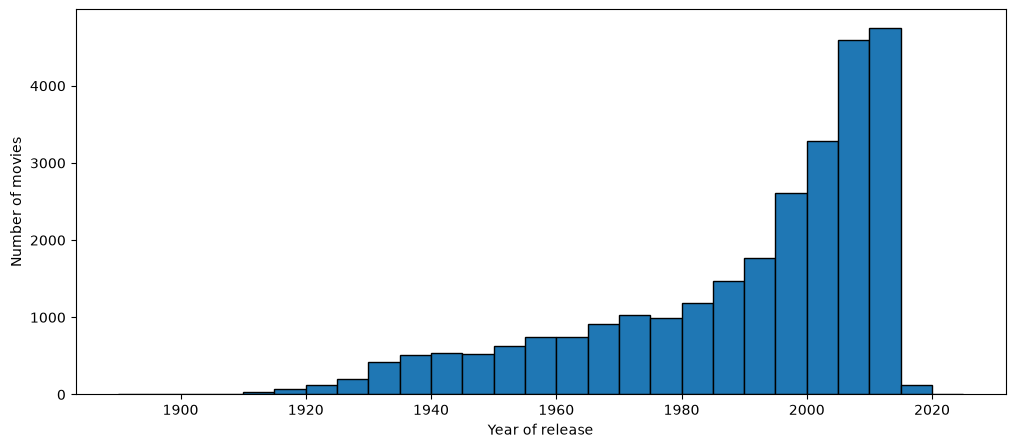

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.hist(movies_df['year'].dropna(), bins=range(1890, 2030, 5), edgecolor='black')
plt.xlabel("Year of release")
plt.ylabel("Number of movies")
plt.show()

In [4]:
movies_df.to_parquet('../data/processed/movies_df.parquet')